# Layouts: non-periodic areas filled with many shapes

A `Layout` is the non-periodic counterpart of `UnitCell`: a finite **domain** (any `Shape`) filled with
**atoms** held in a spatially indexed `ShapeSet`. This notebook covers

1. random constrained packing (`RandomSites` + `SamplerSource`),
2. a field-driven layout on a hexagonal grid (`LatticeSites` + `ParametricSource`),
3. analysis and checks (`LayoutAnalyzer`),
4. a short tiled optimization loop (`make_learnable`, `tiles`, `containment_penalty`).

In [1]:
import math
import matplotlib.pyplot as plt
import torch

from metashapes import Lattice
from metashapes.shape import Ellipse, Rectangle
from metashapes.generators import GeneratorConfig
from metashapes.layout import (Layout, LayoutAnalyzer, LayoutConfig, LayoutGenerator,
                               LatticeSites, ParametricSource, RandomSites, Regions,
                               SamplerSource, make_learnable)

def show(layout, pixel_size, ax=None, title=None):
    ax = ax or plt.gca()
    ax.imshow(layout.mask(pixel_size=pixel_size).cpu().numpy(), origin="lower",
              extent=layout.extent(), cmap="gray_r")
    ax.set_aspect("equal"); ax.set_title(title or f"{len(layout)} atoms")

## 1. Random constrained packing

Random sequential addition: candidates are drawn uniformly in the domain, an atom is sampled by the existing
per-primitive samplers inside a small reference box (`atom_box`), and it is accepted only if it is fully inside
the domain shrunk by `edge_margin` and at least `min_gap` from every accepted atom. Generation stops on
`target_fill_fraction` or when `max_consecutive_failures` candidates in a row are rejected (saturation).

{'num_shapes': (1206, 1306), 'fill_fraction': (0.22191095515424525, 0.2332718323222701)}
rejections: {'gap_violation': 37261, 'outside_domain': 2439} saturated: 2


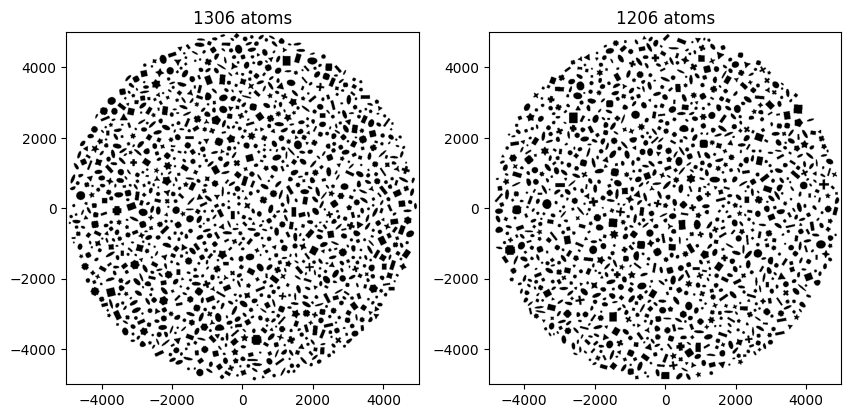

In [12]:
domain = Ellipse(center=(0, 0), axes=(10_000, 10_000))     # 10 µm circular aperture (nm units)

gen = LayoutGenerator(
    LayoutConfig(seed=0, target_count=2, min_gap=50, edge_margin=50, target_fill_fraction=0.30,
                 max_consecutive_failures=500),
    sites=RandomSites(),
    source=SamplerSource(
        GeneratorConfig(allowed_shapes=("Rectangle", "Ellipse", "Cross", "Egg", "Star"), 
                        min_feature_size=30, min_shape_size=50, 
                        shape_param_ranges={
        "Star":  {"outer_corner_radius": (0, 15), "inner_corner_radius": (0, 10)},
        "Cross": {"outer_corner_radius": (5, 15),  "inner_corner_radius": (0, 5)},
        "Rectangle": {"corner_radius": (0, 10)},   # single-radius shapes
    },),
        atom_box=(300, 300),
    ),
)
batch = gen.generate(domain)
print(batch.report.parameter_ranges)
print("rejections:", batch.report.metadata["site_rejections"], "saturated:", batch.report.metadata["saturated"])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, lay in zip(axes, batch.layouts):
    show(lay, pixel_size=10, ax=ax)

## 2. Field-driven layout on a hexagonal grid

Shape parameters can be functions of position. Here the disc radius follows a radial "phase" ramp, and the
left half of the aperture uses rectangles instead via `Regions`. Sites whose atom doesn't fit inside the
domain stay empty.

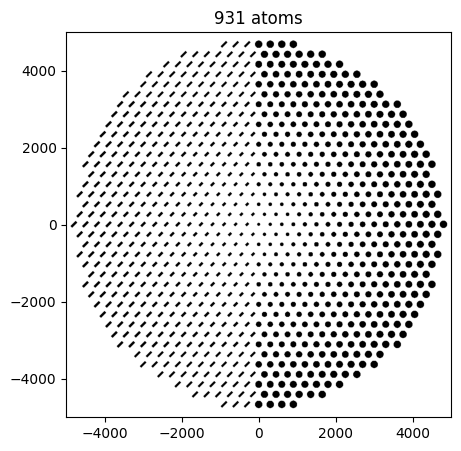

In [13]:
phase = lambda x, y: (math.hypot(x, y) / 5_000) * 2 * math.pi
radius = lambda x, y: 40 + 60 * phase(x, y) / (2 * math.pi)

discs = ParametricSource(Ellipse, {"axes": lambda x, y: (2 * radius(x, y),) * 2})
bars = ParametricSource(Rectangle, {"size": lambda x, y: (2 * radius(x, y), 60.0), "angle": 45.0})
left = Rectangle(center=(-2_500, 0), size=(5_000, 10_000))

gen = LayoutGenerator(LayoutConfig(edge_margin=100), sites=LatticeSites(Lattice.hexagonal(300)),
                      source=Regions([(left, bars)], default=discs))
field_layout = gen.generate_one(domain)
plt.figure(figsize=(5, 5)); show(field_layout, pixel_size=10)

## 3. Analysis and checks

`LayoutAnalyzer` measures fill fraction, the minimum gap (STRtree nearest neighbour, non-periodic), feature
size and clearance from the domain edge. Generated layouts never violate containment; hand-built ones can be
checked with `layout.check(...)` / `layout.violations(...)`.

In [14]:
analyzer = LayoutAnalyzer(min_gap=50, min_feature_size=60, edge_margin=150)
print(analyzer.metrics(batch.layouts[0]))
print("check:", analyzer.check(batch.layouts[0]))
print("field layout:", LayoutAnalyzer(edge_margin=100).metrics(field_layout))

LayoutMetrics(n_shapes=1306, fill_fraction=0.2332718323222696, min_gap=50.004604838132266, min_feature_size=30.0, min_edge_clearance=50.113791006231885, n_outside=75, n_clipped_features=0)
check: ['outside_domain: 75 atom(s) not fully inside the domain (edge_margin 150.0)', 'min_feature_size 30 < required 60']
field layout: LayoutMetrics(n_shapes=931, fill_fraction=0.17438260905991876, min_gap=96.3230758239856, min_feature_size=60.0, min_edge_clearance=102.27665623945057, n_outside=0, n_clipped_features=0)


## 4. Optimization: learnability is assigned after generation

Generators return plain shapes (buffers only). `make_learnable` turns chosen buffers into `nn.Parameter`s.
The loss is evaluated tile by tile (the full domain raster is never held in memory) and gradients accumulate
across tiles. `containment_penalty` pushes atoms that drift over the edge back inside; rendering clips to the
domain in any case. Here we grow every disc of the field layout toward a target fill fraction.

fill 0.188 -> 0.397 (target 0.4)
violations: []


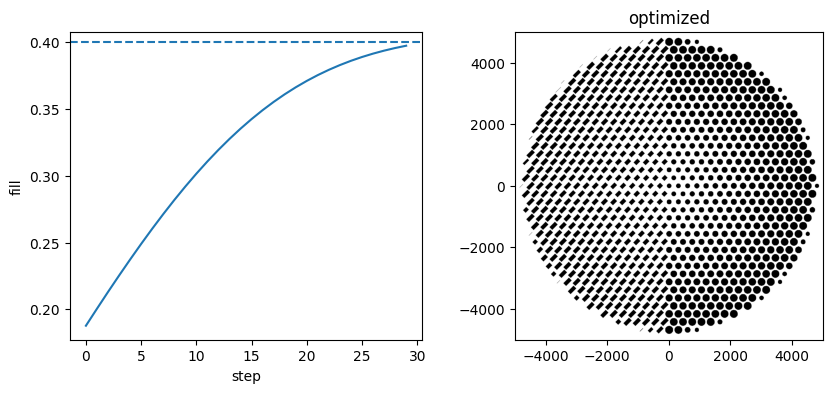

In [15]:
lay = gen.generate_one(domain)
make_learnable(lay.scene, names=("axes", "size"))
lay.scene.skin = 20.0           # let atoms drift 10 nm before the index is rebuilt
opt = torch.optim.Adam(lay.parameters(), lr=5.0)
sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.95)

pixel, target = 10.0, 0.40
domain_px = math.pi * 5_000**2 / pixel**2
history = []
for step in range(30):
    opt.zero_grad()
    fill = 0.0                  # the objective is non-linear in total fill, so sum tiles first
    for t in lay.tiles(2_500, pixel_size=pixel):
        m = lay.mask(bounds=t.bounds, pixel_size=pixel, soft=True)
        part = m.sum() / domain_px
        fill = fill + part
    loss = (fill - target) ** 2 + 1e-4 * lay.containment_penalty(margin=100, pixel_size=pixel)
    loss.backward()
    opt.step()
    sched.step()
    history.append(float(fill))

print(f"fill {history[0]:.3f} -> {history[-1]:.3f} (target {target})")
print("violations:", lay.violations(margin=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history); axes[0].axhline(target, ls="--"); axes[0].set_xlabel("step"); axes[0].set_ylabel("fill")
show(lay, pixel_size=10, ax=axes[1], title="optimized")

For full-scale layouts, call `.backward()` inside the tile loop instead of summing first, so each tile's
graph is freed before the next one is built:

```python
for t in layout.tiles(10_000, pixel_size=5):
    objective(layout.mask(bounds=t.bounds, pixel_size=5, soft=True), t).backward()
```

Large layouts are saved with the columnar format (`metashapes.adapters.npz.save_layouts_npz`); YAML
(`save_layouts`, `save_layout_batch`) is convenient for small ones.